# Cross-Sectional Momentum in US Equities

This notebook investigates whether a stock's **relative past performance** contains information about its subsequent returns.

It backtests a monthly, dollar-neutral long-short momentum strategy on S&P 500 stocks and studies:

- baseline performance and where the return comes from (long vs short book)
- lookback and portfolio-breadth sensitivity
- turnover and transaction costs
- out-of-sample performance and statistical significance
- subperiod behaviour and return autocorrelation
- factor exposure (is there any alpha beyond known factors?)

> **Research question:** Does cross-sectional equity momentum generate persistent long-short returns after transaction costs, across time periods and signal specifications, and are those returns explained by known risk factors?

**Important:** This is a student research project. The goal is to understand the process of quantitative strategy research rather than to build a production trading system. The conclusions at the bottom are generated from the results computed in this notebook.

## 1. Setup

In [2]:
import io
import os
import urllib.request
import zipfile
from io import StringIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels.api as sm
import yfinance as yf
from IPython.display import Markdown, display
from scipy import stats

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
os.makedirs("results", exist_ok=True)

## 2. Data Collection

The stock universe is the **current S&P 500 constituent list** from Wikipedia. This introduces survivorship bias (see Limitations), because only stocks that are in the index *today* are tested historically.

Prices come from `yfinance` with `auto_adjust=True`, so `Close` incorporates split and dividend adjustments. History runs from January 2009 through December 2025.

In [3]:
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
headers = {"User-Agent": "Mozilla/5.0"}

response = requests.get(url, headers=headers)
response.raise_for_status()

sp500_df = pd.read_html(StringIO(response.text))[0]
tickers = sp500_df["Symbol"].str.replace(".", "-", regex=False).tolist()

print("Number of stocks:", len(tickers))

Number of stocks: 503


In [4]:
prices = yf.download(
    tickers,
    start="2009-01-01",
    end="2026-01-01",
    auto_adjust=True,
    group_by="column",
    threads=True,
)
print("Downloaded data shape:", prices.shape)

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
3 Failed downloads:
ERROR:yfinance:['VYLR', 'FDXF', 'HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2009-01-01 -> 2026-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1230786000, endDate = 1767243600")')


Downloaded data shape: (4276, 2518)


## 3. Price Data Preparation

Only adjusted `Close` prices are needed. Stocks have different listing histories, so missing values are expected. I do **not** forward-fill or drop every stock with any missing value; instead, eligibility is evaluated at each rebalance date (a stock needs a valid signal and a valid holding-period return).

Daily prices are converted to month-end prices, which are the basis for signals, rebalancing, and returns.

In [5]:
close = prices["Close"].copy().sort_index()

# Tickers for which Yahoo returned no usable history. They drop out automatically
# (no valid signal), but they are real current constituents, so list them explicitly.
no_data = close.columns[close.isna().all()].tolist()
print("Tickers with no price data (excluded):", no_data)

history_start = close.notna().idxmax()
print("\nLatest-listed stocks in the universe:")
print(history_start[~close.isna().all()].sort_values().tail(5))

month_end_prices = close.resample("ME").last()
print("\nMonthly price matrix:", month_end_prices.shape)

Tickers with no price data (excluded): ['FDXF', 'HONA', 'VYLR']

Latest-listed stocks in the universe:
Ticker
RDDT   2024-03-21
SOLV   2024-03-26
GEV    2024-03-27
SNDK   2025-02-13
Q      2025-10-27
dtype: datetime64[ns]

Monthly price matrix: (204, 503)


## 4. Momentum Signal

A $k$–1 month momentum signal ranks stocks by their return from month $t-k$ to month $t-1$, **skipping the most recent month**:

$$
Momentum_t^{(k)} = \frac{P_{t-1}}{P_{t-k}} - 1
$$

The portfolio formed at the end of month $t$ therefore uses prices only through month $t-1$, and is held from the end of month $t$ to the end of month $t+1$. This separation between signal formation and the holding period avoids look-ahead bias. The baseline is $k=12$; $k=3$ and $k=6$ are used in the sensitivity analysis.

In [6]:
def momentum_signal(month_end_prices, lookback):
    """k-1 month momentum: P(t-1) / P(t-k) - 1, with the most recent month skipped."""
    return month_end_prices.shift(1) / month_end_prices.shift(lookback) - 1


momentum_12_1 = momentum_signal(month_end_prices, 12)

**Sanity check:** the highest and lowest momentum stocks at one historical date (inspection only; these are not selected by hand).

In [7]:
example_signal = momentum_12_1.loc["2020-12-31"].dropna()

print("Top 10 momentum stocks (Dec 2020):")
display(example_signal.nlargest(10).to_frame("Momentum"))
print("Bottom 10 momentum stocks (Dec 2020):")
display(example_signal.nsmallest(10).to_frame("Momentum"))

Top 10 momentum stocks (Dec 2020):


,Momentum
Ticker,
MRNA,6.8088
TSLA,5.7841
XYZ,2.3721
BE,2.2825
TWLO,2.2569
CRWD,2.0736
CVNA,1.7182
DDOG,1.6183
NVDA,1.2813


Bottom 10 momentum stocks (Dec 2020):


,Momentum
Ticker,
NCLH,-0.6085
OXY,-0.6054
CCL,-0.6023
FANG,-0.5542
APA,-0.4886
UAL,-0.4886
OKE,-0.4715
WFC,-0.4712
SLB,-0.4681


## 5. Portfolio Construction and Backtest

At each month-end rebalance:

1. Rank eligible stocks by momentum.
2. Buy the top `cutoff` fraction and short the bottom `cutoff` fraction (baseline 10%).
3. Equal-weight within each side: +100% long, -100% short, so the book is **dollar-neutral** with 200% gross exposure.
4. Hold until the next month-end.

If a selected stock has no valid holding-period return, the long and short sides are separately renormalized so the remaining positions keep their intended exposure.

The function returns the monthly return of the long book, the short book, and the total (long book P&L + short book P&L, each as a fraction of equity), plus the target weights at each rebalance date. Dollar-neutral does not mean beta-neutral; factor exposure is tested in Section 11.

In [8]:
def run_momentum_backtest(signal, month_end_prices, cutoff=0.10):
    """
    Monthly long-short backtest.

    Returns
    -------
    legs    : DataFrame indexed by RETURN date with columns long, short, total
    weights : DataFrame indexed by REBALANCE date (target weights, all stocks)
    """
    cols = month_end_prices.columns
    dates = signal.index
    legs, weights = {}, {}

    for i in range(len(dates) - 1):
        d, nxt = dates[i], dates[i + 1]

        sig = signal.loc[d].dropna()
        if len(sig) < 10:
            continue
        n_side = int(len(sig) * cutoff)
        if n_side == 0:
            continue

        w = pd.Series(0.0, index=cols)
        w.loc[sig.nlargest(n_side).index] = 1 / n_side
        w.loc[sig.nsmallest(n_side).index] = -1 / n_side

        r = month_end_prices.loc[nxt] / month_end_prices.loc[d] - 1
        w = w.where(r.notna(), 0.0)                 # drop positions with no holding-period return
        r = r.fillna(0.0)

        long_mask, short_mask = w > 0, w < 0
        if long_mask.any():
            w.loc[long_mask] /= w.loc[long_mask].sum()
        if short_mask.any():
            w.loc[short_mask] /= -w.loc[short_mask].sum()

        long_ret = float((w.clip(lower=0) * r).sum())
        short_ret = float((w.clip(upper=0) * r).sum())    # P&L of the short book
        legs[nxt] = {"long": long_ret, "short": short_ret, "total": long_ret + short_ret}
        weights[d] = w

    return pd.DataFrame(legs).T, pd.DataFrame(weights).T


bt, portfolio_weights = run_momentum_backtest(momentum_12_1, month_end_prices, cutoff=0.10)
monthly_returns = bt["total"].rename("portfolio_return")

print("Backtest months:", len(monthly_returns))
print("First return:", monthly_returns.index.min().date(), "| Last return:", monthly_returns.index.max().date())

Backtest months: 191
First return: 2010-02-28 | Last return: 2025-12-31


**Checks.** (1) Exposure: every rebalance should be dollar-neutral with 200% gross. (2) No look-ahead: the signal at date $t$ must not change if every price from $t$ onward is deleted.

In [9]:
net_exposure = portfolio_weights.sum(axis=1)
gross_exposure = portfolio_weights.abs().sum(axis=1)
print(f"Net exposure:   max |net| = {net_exposure.abs().max():.4f}")
print(f"Gross exposure: min = {gross_exposure.min():.2f}, max = {gross_exposure.max():.2f}")

test_date = pd.Timestamp("2020-12-31")
truncated = month_end_prices.copy()
truncated.loc[test_date:] = np.nan                  # remove all information from test_date onward
pd.testing.assert_series_equal(
    momentum_signal(truncated, 12).loc[test_date],
    momentum_12_1.loc[test_date],
)
print("No look-ahead: the 2020-12-31 signal uses no price from 2020-12-31 or later.")

Net exposure:   max |net| = 0.0000
Gross exposure: min = 2.00, max = 2.00
No look-ahead: the 2020-12-31 signal uses no price from 2020-12-31 or later.


## 6. Performance Metrics and Baseline Results

The Sharpe ratio uses monthly returns, a 0% risk-free rate (the strategy is self-financing, so returns are already excess returns), and is annualized by $\sqrt{12}$. All results below are **gross of transaction costs** until Section 8.

In [10]:
def calculate_metrics(returns):
    returns = returns.dropna()
    cumulative = (1 + returns).cumprod()
    drawdown = cumulative / cumulative.cummax() - 1
    return {
        "Annualized Return": (1 + returns).prod() ** (12 / len(returns)) - 1,
        "Annualized Volatility": returns.std() * np.sqrt(12),
        "Sharpe": returns.mean() / returns.std() * np.sqrt(12),
        "Max Drawdown": drawdown.min(),
    }


baseline_metrics = calculate_metrics(monthly_returns)
display(pd.Series(baseline_metrics, name="Baseline (12-1, top/bottom 10%, gross)").to_frame())

annual_returns = monthly_returns.resample("YE").apply(lambda x: (1 + x).prod() - 1)
display(annual_returns.to_frame("Annual Return"))

,"Baseline (12-1, top/bottom 10%, gross)"
Annualized Return,0.0180
Annualized Volatility,0.1763
Sharpe,0.1901
Max Drawdown,-0.4957


,Annual Return
2010-12-31,0.2101
2011-12-31,0.0317
2012-12-31,-0.0008
2013-12-31,0.1657
2014-12-31,-0.0607
2015-12-31,0.2114
2016-12-31,-0.2781
2017-12-31,0.0152
2018-12-31,0.1153
2019-12-31,-0.0821


## 7. Where Does the Return Come From? Long Book vs Short Book

Each month's P&L split into the long book and the short book (contributions as a fraction of equity).

In [11]:
leg_table = pd.DataFrame({
    "Mean monthly P&L": bt.mean(),
    "Annualized vol": bt.std() * np.sqrt(12),
    "Sharpe": bt.mean() / bt.std() * np.sqrt(12),
})
leg_table.index = ["Long book", "Short book", "Total"]
display(leg_table)

,Mean monthly P&L,Annualized vol,Sharpe
Long book,0.0205,0.1899,1.2983
Short book,-0.0178,0.2361,-0.9024
Total,0.0028,0.1763,0.1901


## 8. Robustness: Lookback and Portfolio Breadth

I test lookbacks of 3-1, 6-1, and 12-1 months and portfolio cutoffs of 5%, 10%, and 20% in a single grid.

Two points on interpretation:

- **Same sample for every cell.** Shorter lookbacks have valid signals earlier (3-1 starts in 2009, 12-1 in 2010). All cells are evaluated over the baseline's dates so that they differ only in the signal and breadth, not in the period covered.
- **The grid is for sensitivity, not selection.** The 12-1 / 10% baseline was fixed in advance; picking the best cell afterwards would be data-snooping.

In [12]:
lookbacks = [3, 6, 12]
cutoffs = [0.05, 0.10, 0.20]
common_index = monthly_returns.index

grid = {}
for lb in lookbacks:
    sig = momentum_signal(month_end_prices, lb)
    for c in cutoffs:
        r = run_momentum_backtest(sig, month_end_prices, cutoff=c)[0]["total"]
        grid[(f"{lb}-1", f"{int(c * 100)}%")] = calculate_metrics(r.loc[common_index])

grid_df = pd.DataFrame(grid).T
grid_df.index.names = ["Lookback", "Breadth"]

row_order = [f"{lb}-1" for lb in lookbacks]
col_order = [f"{int(c * 100)}%" for c in cutoffs]

def grid_view(metric):
    return grid_df[metric].unstack("Breadth").loc[row_order, col_order]

grid_ret = grid_view("Annualized Return")
grid_sharpe = grid_view("Sharpe")
grid_vol = grid_view("Annualized Volatility")
grid_mdd = grid_view("Max Drawdown")

assert np.isclose(grid_ret.loc["12-1", "10%"], baseline_metrics["Annualized Return"])

print("Annualized return (gross)"); display(grid_ret)
print("Sharpe ratio (gross)");      display(grid_sharpe)
print("Annualized volatility");     display(grid_vol)
print("Max drawdown");              display(grid_mdd)

Annualized return (gross)


Breadth,5%,10%,20%
Lookback,,,
3-1,-0.0220,-0.0212,-0.0184
6-1,0.0499,0.0050,-0.0032
12-1,0.0474,0.0180,0.0157


Sharpe ratio (gross)


Breadth,5%,10%,20%
Lookback,,,
3-1,-0.0115,-0.0616,-0.0859
6-1,0.3365,0.1132,0.0384
12-1,0.3179,0.1901,0.1831


Annualized volatility


Breadth,5%,10%,20%
Lookback,,,
3-1,0.2000,0.1549,0.1253
6-1,0.2108,0.1661,0.1279
12-1,0.2294,0.1763,0.1360


Max drawdown


Breadth,5%,10%,20%
Lookback,,,
3-1,-0.5916,-0.4992,-0.4558
6-1,-0.4189,-0.3765,-0.2924
12-1,-0.5375,-0.4957,-0.3553


## 9. Turnover and Transaction Costs

**Traded notional** at a rebalance is $\sum_i |w^{new}_i - w^{drifted}_i|$ as a fraction of equity, where $w^{drifted}$ is the previous portfolio after one month of price moves. Two details matter:

- The trade is measured against the **drifted** portfolio, not the previous target weights.
- The book is 100% long and 100% short, so the full sum (not half of it) is the dollar amount traded. Costs are quoted in basis points **per dollar traded**. (One-way turnover, $\tfrac12\sum|\Delta w|$, is reported for reference only.)

The cost of the trade at date $t$ is subtracted from the return earned **after** $t$. The first rebalance builds the book from cash and is included. These are simple proportional-cost sensitivities, not a market-impact model.

In [13]:
def traded_notional(weights, month_end_prices):
    """
    Dollars traded at each rebalance (fraction of equity), indexed by the date of the
    return that the trade's cost should be charged against (the following month-end).
    """
    me_index = month_end_prices.index
    prev = pd.Series(0.0, index=weights.columns)           # start from cash
    traded = {}
    for d in weights.index:
        w = weights.loc[d]
        nxt = me_index[me_index.get_loc(d) + 1]
        traded[nxt] = float((w - prev).abs().sum())
        r = (month_end_prices.loc[nxt] / month_end_prices.loc[d] - 1).reindex(weights.columns).fillna(0.0)
        prev = w * (1 + r) / (1 + float((w * r).sum()))     # drift weights through the holding period
    return pd.Series(traded, name="traded_notional")


def net_of_costs(gross, traded, bps):
    t = traded.reindex(gross.index)
    assert t.notna().all(), "missing traded notional for some return dates"
    return gross - t * bps / 1e4


traded = traded_notional(portfolio_weights, month_end_prices)
assert traded.index.equals(monthly_returns.index)

print(f"Average traded notional per month (excl. initial build): {traded.iloc[1:].mean():.1%} of equity")
print(f"Equivalent one-way turnover:                              {traded.iloc[1:].mean() / 2:.1%}")
print(f"Median / max traded notional:                             {traded.iloc[1:].median():.1%} / {traded.iloc[1:].max():.1%}")

Average traded notional per month (excl. initial build): 126.7% of equity
Equivalent one-way turnover:                              63.3%
Median / max traded notional:                             125.1% / 273.6%


In [14]:
bps_grid = [0, 5, 10, 15, 20, 25, 30, 50]
cost_table = pd.DataFrame(
    {f"{b} bps": calculate_metrics(net_of_costs(monthly_returns, traded, b)) for b in bps_grid}
).T
display(cost_table)

# Break-even: where annualized net return crosses zero (linear interpolation on the grid)
ann = cost_table["Annualized Return"].values
if ann[0] <= 0:
    breakeven_bps = None
    print("No positive gross edge, so no break-even cost.")
elif ann[-1] > 0:
    breakeven_bps = np.inf
    print(f"Edge is still positive at the highest tested cost ({bps_grid[-1]} bps).")
else:
    breakeven_bps = float(np.interp(0.0, ann[::-1], np.array(bps_grid)[::-1]))   # ann decreases with bps
    print(f"Approximate break-even cost: {breakeven_bps:.1f} bps per dollar traded")

,Annualized Return,Annualized Volatility,Sharpe,Max Drawdown
0 bps,0.0180,0.1763,0.1901,-0.4957
5 bps,0.0103,0.1763,0.1468,-0.5274
10 bps,0.0026,0.1763,0.1035,-0.5572
15 bps,-0.0051,0.1764,0.0603,-0.5851
20 bps,-0.0126,0.1764,0.0170,-0.6113
25 bps,-0.0202,0.1765,-0.0262,-0.6359
30 bps,-0.0276,0.1765,-0.0694,-0.6589
50 bps,-0.0570,0.1768,-0.2418,-0.7605


Approximate break-even cost: 11.7 bps per dollar traded


## 10. Out-of-Sample Evaluation

- **Development:** 2010-2022
- **Out-of-sample (OOS):** 2023-2025

The specification (12-1, top/bottom 10%) was fixed in advance and is not re-tuned. One caveat: the sensitivity grid in Section 8 was computed on the full sample, which includes 2023-2025, so this is a holdout rather than a completely untouched test.

In [15]:
dev_returns = monthly_returns.loc[:"2022-12-31"]
oos_returns = monthly_returns.loc["2023-01-01":]

print(f"Development: {dev_returns.index.min().date()} to {dev_returns.index.max().date()} ({len(dev_returns)} months)")
print(f"OOS:         {oos_returns.index.min().date()} to {oos_returns.index.max().date()} ({len(oos_returns)} months)")

oos_table = pd.DataFrame({
    "Development": calculate_metrics(dev_returns),
    "OOS 2023-2025": calculate_metrics(oos_returns),
})
display(oos_table)

print("OOS performance net of costs:")
oos_cost_table = pd.DataFrame(
    {f"{b} bps": calculate_metrics(net_of_costs(oos_returns, traded, b)) for b in [0, 10, 25, 50]}
).T
display(oos_cost_table)

Development: 2010-02-28 to 2022-12-31 (155 months)
OOS:         2023-01-31 to 2025-12-31 (36 months)


,Development,OOS 2023-2025
Annualized Return,0.0127,0.0411
Annualized Volatility,0.1671,0.2138
Sharpe,0.1596,0.2945
Max Drawdown,-0.4643,-0.1326


OOS performance net of costs:


,Annualized Return,Annualized Volatility,Sharpe,Max Drawdown
0 bps,0.0411,0.2138,0.2945,-0.1326
10 bps,0.0259,0.2138,0.2257,-0.1346
25 bps,0.0035,0.2139,0.1225,-0.1486
50 bps,-0.0328,0.2139,-0.0494,-0.1807


## 11. Statistical Significance

The OOS window has only 36 monthly observations, so inference is fragile. I report:

- a naive i.i.d. t-test of the mean monthly return (for reference),
- the same test with **Newey-West (HAC)** standard errors, which allow for autocorrelation and heteroskedasticity, and
- a **moving-block bootstrap** (6-month blocks) confidence interval for the annualized Sharpe ratio.

Samples: the full period (gross), the OOS window (gross), and the full period net of 10 bps per dollar traded.

In [16]:
def hac_lags(n):
    return int(np.floor(4 * (n / 100) ** (2 / 9)))          # Newey-West rule of thumb


def mean_test(returns):
    y = returns.dropna()
    n = len(y)
    naive_t, naive_p = stats.ttest_1samp(y, 0.0)
    res = sm.OLS(y.values, np.ones((n, 1))).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags(n)})
    ci_low, ci_high = res.conf_int()[0]
    return {
        "Months": n, "Mean monthly": y.mean(),
        "Naive t": naive_t, "Naive p": naive_p,
        "HAC t": res.tvalues[0], "HAC p": res.pvalues[0],
        "HAC 95% CI low": ci_low, "HAC 95% CI high": ci_high,
    }


def block_bootstrap_sharpe(returns, block=6, n_boot=10_000, seed=0):
    x = returns.dropna().values
    n = len(x)
    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(n / block))
    starts = rng.integers(0, n - block + 1, size=(n_boot, n_blocks))
    idx = (starts[:, :, None] + np.arange(block)[None, None, :]).reshape(n_boot, -1)[:, :n]
    s = x[idx]
    sharpes = s.mean(axis=1) / s.std(axis=1, ddof=1) * np.sqrt(12)
    return np.percentile(sharpes, [2.5, 97.5]), sharpes


samples = {
    "Full sample (gross)": monthly_returns,
    "OOS 2023-2025 (gross)": oos_returns,
    "Full sample (net, 10 bps)": net_of_costs(monthly_returns, traded, 10),
}

stat_table, boot_table = {}, {}
for name, r in samples.items():
    stat_table[name] = mean_test(r)
    (lo, hi), sh = block_bootstrap_sharpe(r)
    boot_table[name] = {
        "Sharpe": r.mean() / r.std() * np.sqrt(12),
        "Bootstrap 95% low": lo, "Bootstrap 95% high": hi,
        "P(Sharpe <= 0)": (sh <= 0).mean(),
    }

stat_table = pd.DataFrame(stat_table).T
boot_table = pd.DataFrame(boot_table).T
display(stat_table)
display(boot_table)

,Months,Mean monthly,Naive t,Naive p,HAC t,HAC p,HAC 95% CI low,HAC 95% CI high
Full sample (gross),191.0000,0.0028,0.7583,0.4492,0.8656,0.3867,-0.0035,0.0091
OOS 2023-2025 (gross),36.0000,0.0052,0.5101,0.6132,0.5350,0.5927,-0.0140,0.0245
"Full sample (net, 10 bps)",191.0000,0.0015,0.4130,0.6801,0.4705,0.6380,-0.0048,0.0079


,Sharpe,Bootstrap 95% low,Bootstrap 95% high,P(Sharpe <= 0)
Full sample (gross),0.1901,-0.2732,0.5889,0.2347
OOS 2023-2025 (gross),0.2945,-0.3762,1.7780,0.0896
"Full sample (net, 10 bps)",0.1035,-0.3606,0.4996,0.3766


## 12. Subperiod Analysis and Return Autocorrelation

Does the strategy behave similarly across periods? The full sample is split into three subperiods. Autocorrelation of the monthly return series is checked as a basic diagnostic of serial dependence (it also motivates the HAC standard errors above).

In [17]:
subperiods = {
    "2010-2015": monthly_returns.loc["2010-01-01":"2015-12-31"],
    "2016-2020": monthly_returns.loc["2016-01-01":"2020-12-31"],
    "2021-2025": monthly_returns.loc["2021-01-01":"2025-12-31"],
}
subperiod_table = pd.DataFrame({k: calculate_metrics(v) for k, v in subperiods.items()}).T
display(subperiod_table)

lags = [1, 3, 6, 12]
autocorr_table = pd.DataFrame(
    {"Full sample": [monthly_returns.autocorr(lag=l) for l in lags],
     "OOS": [oos_returns.autocorr(lag=l) for l in lags]},
    index=pd.Index(lags, name="Lag"),
)
display(autocorr_table)

,Annualized Return,Annualized Volatility,Sharpe,Max Drawdown
2010-2015,0.0889,0.1318,0.7134,-0.1501
2016-2020,-0.0729,0.2005,-0.2771,-0.3165
2021-2025,0.0323,0.1954,0.2608,-0.2871


,Full sample,OOS
Lag,,
1,-0.0678,0.0346
3,-0.0183,0.0270
6,0.0811,0.0238
12,0.0577,-0.2469


## 13. Factor Regressions: Is There Any Alpha?

Dollar-neutral does not mean factor-neutral. I regress monthly strategy returns on factors from Ken French's data library:

1. CAPM (Mkt-RF)
2. Fama-French 5 factors (Mkt-RF, SMB, HML, RMW, CMA)
3. FF5 + momentum (UMD)

Returns are not reduced by the risk-free rate (the book is self-financing). Standard errors are Newey-West. Expect a large positive loading on UMD in model 3, since the strategy *is* a momentum strategy; the informative numbers are alpha in models 1-2 and what remains in model 3.

If the download fails, fetch `F-F_Research_Data_5_Factors_2x3_CSV.zip` and `F-F_Momentum_Factor_CSV.zip` from Ken French's website manually and adapt `load_french` to read the local files; the rest of the notebook skips this section gracefully.

In [18]:
FF_BASE = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"


def parse_french_csv(text):
    """Parse the monthly block of a Ken French CSV into decimal returns on a month-end index."""
    header, rows = None, []
    for line in text.splitlines():
        parts = [p.strip() for p in line.split(",")]
        if len(parts[0]) == 6 and parts[0].isdigit():
            rows.append(parts)
        elif rows:                                   # first non-data line after the monthly block
            break
        elif parts[0] == "" and len(parts) > 1:
            header = parts[1:]
    df = pd.DataFrame(rows, columns=["date"] + header).set_index("date")
    df = df.apply(pd.to_numeric, errors="coerce") / 100.0
    df.index = pd.to_datetime(df.index, format="%Y%m") + pd.offsets.MonthEnd(0)
    df.columns = [c.strip() for c in df.columns]
    return df


def load_french(zip_name):
    req = urllib.request.Request(FF_BASE + zip_name, headers={"User-Agent": "Mozilla/5.0"})
    raw = urllib.request.urlopen(req).read()
    with zipfile.ZipFile(io.BytesIO(raw)) as z:
        return parse_french_csv(z.read(z.namelist()[0]).decode("latin-1"))


try:
    ff5 = load_french("F-F_Research_Data_5_Factors_2x3_CSV.zip")
    umd = load_french("F-F_Momentum_Factor_CSV.zip")
    umd.columns = ["UMD"]
    factors = ff5.join(umd, how="inner")
    print("Factor data:", factors.index.min().date(), "to", factors.index.max().date())
except Exception as e:
    factors = None
    print("Could not load factor data; skipping factor regressions.\nReason:", repr(e))

Factor data: 1963-07-31 to 2026-08-31


In [19]:
def factor_regression(strategy, factors, cols):
    df = pd.concat([strategy.rename("strat"), factors[cols]], axis=1, join="inner").dropna()
    res = sm.OLS(df["strat"], sm.add_constant(df[cols])).fit(
        cov_type="HAC", cov_kwds={"maxlags": hac_lags(len(df))}
    )
    return res, len(df)


factor_table = None
if factors is not None:
    models = {
        "CAPM": ["Mkt-RF"],
        "FF5": ["Mkt-RF", "SMB", "HML", "RMW", "CMA"],
        "FF5 + UMD": ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "UMD"],
    }
    summary = {}
    for name, cols in models.items():
        res, n = factor_regression(monthly_returns, factors, cols)
        out = {"Months": n, "Alpha (ann.)": res.params["const"] * 12, "Alpha t": res.tvalues["const"]}
        for c in cols:
            out[f"beta {c}"] = res.params[c]
            out[f"t {c}"] = res.tvalues[c]
        out["R2"] = res.rsquared
        summary[name] = out
    factor_table = pd.DataFrame(summary)
    display(factor_table)

,CAPM,FF5,FF5 + UMD
Months,191.0000,191.0000,191.0000
Alpha (ann.),0.0686,0.0617,-0.0037
Alpha t,1.8916,1.7067,-0.1956
beta Mkt-RF,-0.2642,-0.1851,0.0264
t Mkt-RF,-2.2315,-1.9453,0.4113
R2,0.0499,0.1652,0.7720
beta SMB,NaN,-0.2849,0.0442
t SMB,NaN,-1.6796,0.5976
beta HML,NaN,-0.4704,0.0424
t HML,NaN,-3.2657,0.6370


## 14. Visualizations

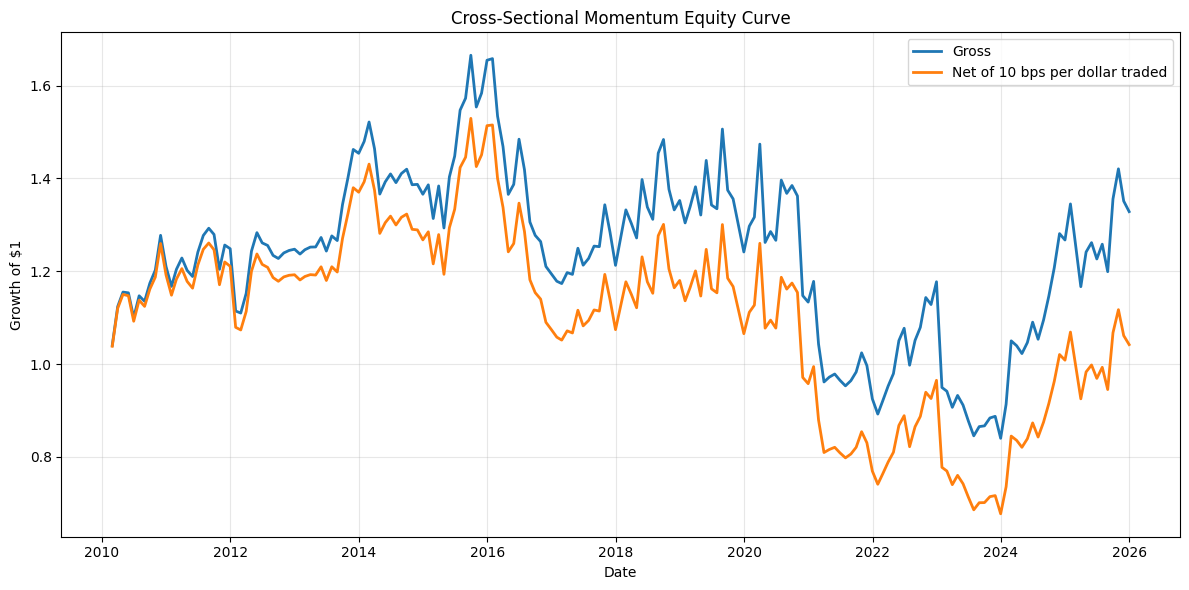

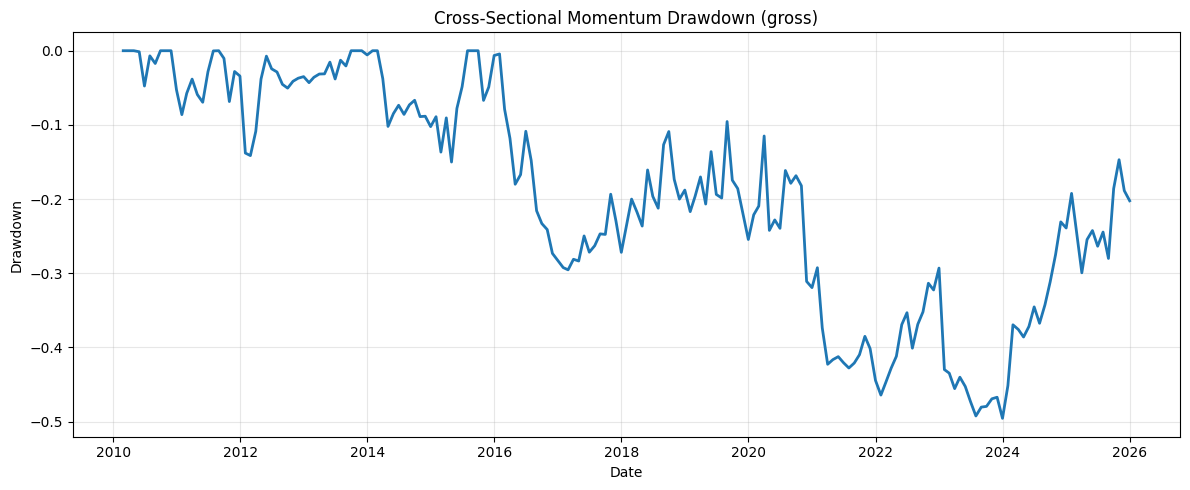

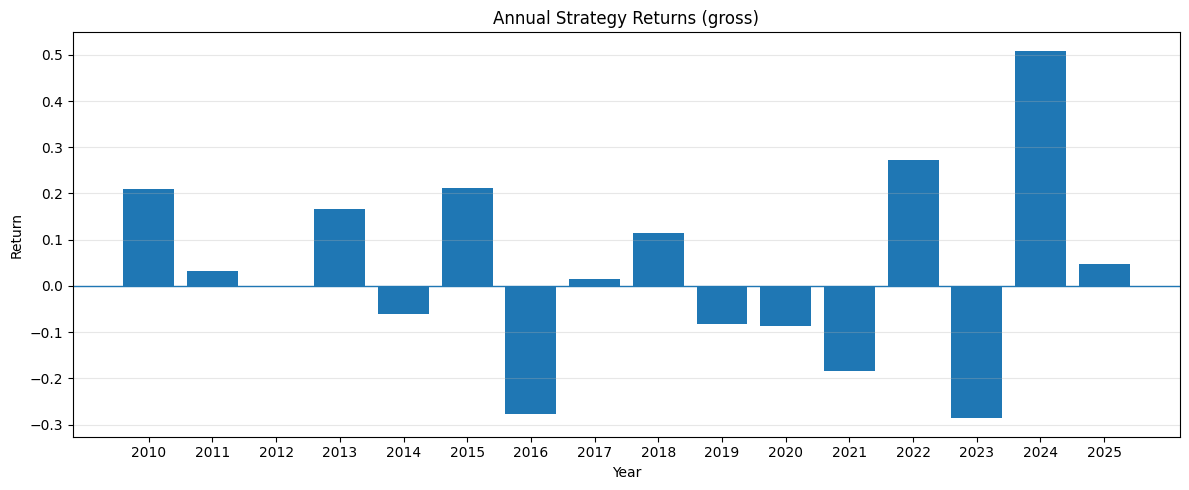

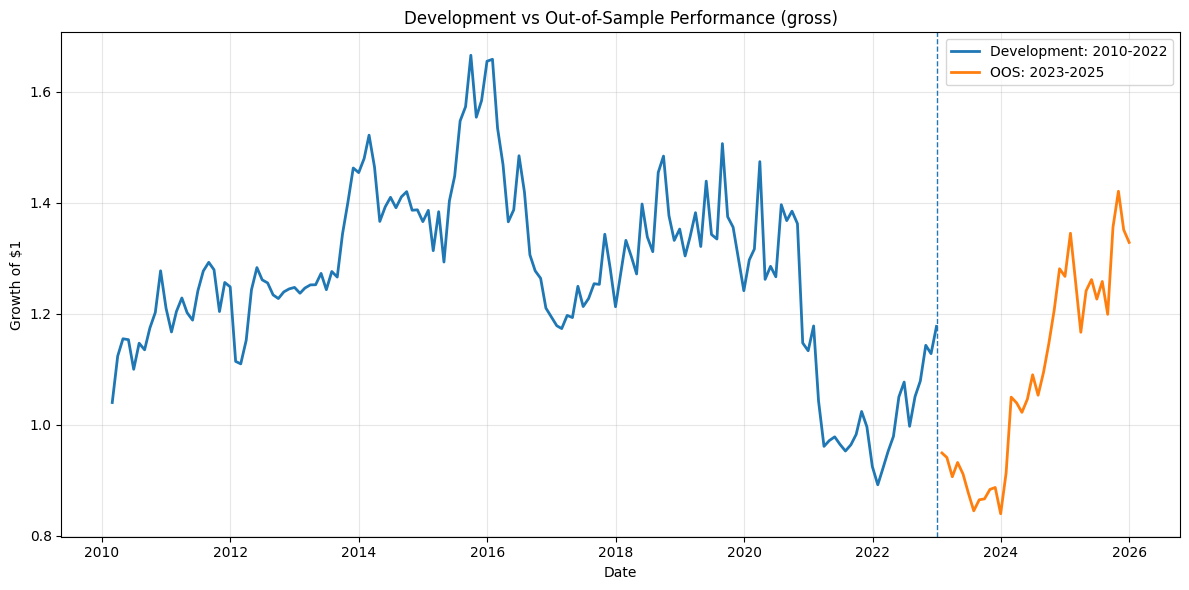

In [20]:
net_10 = net_of_costs(monthly_returns, traded, 10)
equity_gross = (1 + monthly_returns).cumprod()
equity_net = (1 + net_10).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(equity_gross, linewidth=2, label="Gross")
plt.plot(equity_net, linewidth=2, label="Net of 10 bps per dollar traded")
plt.title("Cross-Sectional Momentum Equity Curve")
plt.xlabel("Date"); plt.ylabel("Growth of $1")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig("results/equity_curve.png", dpi=200, bbox_inches="tight")
plt.show()

drawdown = equity_gross / equity_gross.cummax() - 1
plt.figure(figsize=(12, 5))
plt.plot(drawdown, linewidth=2)
plt.title("Cross-Sectional Momentum Drawdown (gross)")
plt.xlabel("Date"); plt.ylabel("Drawdown")
plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig("results/drawdown.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(12, 5))
plt.bar(annual_returns.index.year.astype(str), annual_returns.values)
plt.title("Annual Strategy Returns (gross)")
plt.xlabel("Year"); plt.ylabel("Return")
plt.axhline(0, linewidth=1); plt.grid(True, axis="y", alpha=0.3); plt.tight_layout()
plt.savefig("results/annual_returns.png", dpi=200, bbox_inches="tight")
plt.show()

dev_equity = (1 + dev_returns).cumprod()
oos_equity = (1 + oos_returns).cumprod() * dev_equity.iloc[-1]
plt.figure(figsize=(12, 6))
plt.plot(dev_equity, linewidth=2, label="Development: 2010-2022")
plt.plot(oos_equity, linewidth=2, label="OOS: 2023-2025")
plt.axvline(pd.Timestamp("2023-01-01"), linestyle="--", linewidth=1)
plt.title("Development vs Out-of-Sample Performance (gross)")
plt.xlabel("Date"); plt.ylabel("Growth of $1")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig("results/development_vs_oos.png", dpi=200, bbox_inches="tight")
plt.show()

## 15. Conclusions

The summary below is generated from the results computed above, so the numbers always match the notebook.

In [21]:
def pct(x, d=2):
    return f"{x:.{d}%}"


m = baseline_metrics
lines = []

lines.append(
    f"- **Baseline (gross).** 12-1 momentum, top/bottom 10%, {monthly_returns.index.min():%b %Y} to "
    f"{monthly_returns.index.max():%b %Y}: {pct(m['Annualized Return'])} annualized return, Sharpe "
    f"{m['Sharpe']:.2f}, volatility {pct(m['Annualized Volatility'], 1)}, max drawdown {pct(m['Max Drawdown'], 1)}."
)

n_cells, n_neg = grid_ret.size, int((grid_ret < 0).sum().sum())
lines.append(
    f"- **Sensitivity.** Across the {n_cells} lookback x breadth specifications (same sample), annualized gross "
    f"return ranges from {pct(grid_ret.min().min())} to {pct(grid_ret.max().max())} and Sharpe from "
    f"{grid_sharpe.min().min():.2f} to {grid_sharpe.max().max():.2f}; {n_neg} of {n_cells} are negative. "
    f"The baseline was fixed in advance, not chosen from this grid."
)

if breakeven_bps is None:
    cost_txt = "there is no positive gross edge to erode"
elif np.isinf(breakeven_bps):
    cost_txt = f"the edge survives every tested cost level (up to {bps_grid[-1]} bps)"
else:
    cost_txt = f"the edge is eliminated at roughly {breakeven_bps:.0f} bps per dollar traded"
lines.append(
    f"- **Costs.** The strategy trades about {pct(traded.iloc[1:].mean(), 0)} of equity per month "
    f"(both books), so {cost_txt}."
)

oos_m = oos_table["OOS 2023-2025"]
oos_stat = stat_table.loc["OOS 2023-2025 (gross)"]
oos_boot = boot_table.loc["OOS 2023-2025 (gross)"]
signif = "statistically significant" if oos_stat["HAC p"] < 0.05 else "not statistically distinguishable from zero"
lines.append(
    f"- **Out-of-sample (2023-2025, gross).** {pct(oos_m['Annualized Return'])} annualized, Sharpe "
    f"{oos_m['Sharpe']:.2f}; Newey-West p-value {oos_stat['HAC p']:.2f} and a bootstrap 95% Sharpe interval of "
    f"[{oos_boot['Bootstrap 95% low']:.2f}, {oos_boot['Bootstrap 95% high']:.2f}] over {int(oos_stat['Months'])} "
    f"months, so the result is {signif} at the 5% level."
)

lines.append(
    "- **Stability.** Subperiod Sharpe ratios: "
    + ", ".join(f"{k}: {v:.2f}" for k, v in subperiod_table["Sharpe"].items())
    + f". Annual returns range from {pct(annual_returns.min(), 1)} to {pct(annual_returns.max(), 1)}."
)

if factor_table is not None:
    a = factor_table.loc[["Alpha (ann.)", "Alpha t"]]
    lines.append(
        "- **Factor exposure.** Annualized alpha (HAC t): "
        + ", ".join(f"{c} {pct(a.loc['Alpha (ann.)', c])} ({a.loc['Alpha t', c]:.2f})" for c in a.columns)
        + f". UMD loading in the full model: {factor_table.loc['beta UMD', 'FF5 + UMD']:.2f}."
    )

display(Markdown("\n".join(lines)))

- **Baseline (gross).** 12-1 momentum, top/bottom 10%, Feb 2010 to Dec 2025: 1.80% annualized return, Sharpe 0.19, volatility 17.6%, max drawdown -49.6%.
- **Sensitivity.** Across the 9 lookback x breadth specifications (same sample), annualized gross return ranges from -2.20% to 4.99% and Sharpe from -0.09 to 0.34; 4 of 9 are negative. The baseline was fixed in advance, not chosen from this grid.
- **Costs.** The strategy trades about 127% of equity per month (both books), so the edge is eliminated at roughly 12 bps per dollar traded.
- **Out-of-sample (2023-2025, gross).** 4.11% annualized, Sharpe 0.29; Newey-West p-value 0.59 and a bootstrap 95% Sharpe interval of [-0.38, 1.78] over 36 months, so the result is not statistically distinguishable from zero at the 5% level.
- **Stability.** Subperiod Sharpe ratios: 2010-2015: 0.71, 2016-2020: -0.28, 2021-2025: 0.26. Annual returns range from -28.7% to 50.9%.
- **Factor exposure.** Annualized alpha (HAC t): CAPM 6.86% (1.89), FF5 6.17% (1.71), FF5 + UMD -0.37% (-0.20). UMD loading in the full model: 1.29.

### What this means

A positive backtest is only a starting point. Signal timing, implementation costs, robustness across specifications and periods, statistical uncertainty, and exposure to known factors all matter when judging a systematic strategy, and the results above should be read with each of them in mind rather than from the headline return alone.

### Limitations

- **Survivorship bias.** The universe is today's S&P 500 constituents, so every stock tested "survived" to be in the index. The direction of the bias on the long-short spread is not obvious and was not measured. A point-in-time constituent list or a survivorship-free dataset would be needed to address it.
- **Data quality.** Yahoo Finance is not an institutional data source, and some current constituents returned no usable history (listed in Section 3).
- **Cost model.** Costs are proportional-only: no market impact, borrow costs, financing, or short-sale constraints, and trades execute at month-end closing prices.
- **Short OOS window.** 36 months gives very little statistical power, and the OOS result is dominated by a few large monthly moves.
- **Multiple specifications.** The lookback/breadth grid is exploratory; any single cell picked after the fact would overstate performance.
- **Dollar-neutral, not beta-neutral.** Factor exposure is measured in Section 13, not assumed away.